# QTabGAN, one observable step at a time

**Goal:** follow one bank-data row through encoding, inspect the quantum generator, train a short GAN, select using validation, test once, then make a prediction.

This is a **small teaching run**, not a new benchmark or paper reproduction. It imports the repository's actual model rather than maintaining a second GAN implementation. Default: 1,000 sampled Loan rows, 5 epochs, 8 qubits, 2 original-paper layers, small classical networks, CPU analytic simulation.

Read the explanation above each cell; run cells from top to bottom. Rerunning replaces only this folder's `outputs/demo/` demonstration files. Research results under `results/` are untouched.

Three different jobs: **generator makes rows → discriminator challenges them → a separate Random Forest checks whether the rows are useful.**

In [1]:
from pathlib import Path
import sys, os, json, hashlib, copy, base64, importlib.metadata
import numpy as np
import pandas as pd
import torch
os.environ.setdefault("MPLCONFIGDIR", "/tmp/qtabgan-mpl")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pennylane as qml
from dataclasses import asdict

candidates = [Path(NOTEBOOK_PATH).resolve().parent.parent] if "NOTEBOOK_PATH" in globals() else []
candidates += [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "qtabgan/model.py").is_file())
HERE = ROOT / "simple_walkthrough"
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(HERE))
from qtabgan import QTabGAN, QTabGANConfig
from qtabgan.preprocessing import TabularPreprocessor
from qtabgan.utils import set_seed
from helpers import evaluation_rng, classifier, score, diversity
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, precision_recall_curve

SEED = 42
MAX_ROWS = 1000
EPOCHS = 5
OUT = HERE / "outputs/demo"
OUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
set_seed(SEED)

def table(frame, name=None):
    if name is not None: frame.to_csv(OUT / f"{name}.csv", index=False)
    payload = {"text/plain": frame.to_string(index=False), "text/html": frame.to_html(index=False)}
    if "_emit_display" in globals(): _emit_display(payload)
    else:
        from IPython.display import display
        display(frame)

def picture(fig, name):
    fig.tight_layout(); path = OUT / f"{name}.png"
    fig.savefig(path, dpi=130, bbox_inches="tight"); plt.close(fig)
    if "_emit_display" in globals():
        _emit_display({"image/png": base64.b64encode(path.read_bytes()).decode(), "text/plain": name})
    else:
        from IPython.display import display, Image
        display(Image(filename=str(path)))

print("Project:", ROOT)
print("Demonstration outputs:", OUT)

Project: /home/ojasp/Music/fire298/QTabGAN-initial
Demonstration outputs: /home/ojasp/Music/fire298/QTabGAN-initial/simple_walkthrough/outputs/demo


## 1. What is in the input table?

`PersonalLoan` is the binary label. The other columns are predictors. We do **not** include the label as a predictor for the final classifier. ZIP codes and discrete attributes are categories; numeric quantities are handled separately.

The raw file is already prepared by the repository's data-preparation script (including removal of the ID column). We select a stratified subset to keep this lesson quick. This subset is a teaching choice, not the paper's dataset selection.

In [2]:
DATA = ROOT / "data/loan_prepared.csv"
if not DATA.is_file():
    raise FileNotFoundError("Prepare data/loan_prepared.csv first; see the root README data commands.")
raw = pd.read_csv(DATA)
TARGET = "PersonalLoan"
CATEGORICAL = ["ZIP Code", "Education", "SecuritiesAccount", "CDAccount", "Online", "CreditCard"]
NUMERICAL = [c for c in raw.columns if c not in CATEGORICAL + [TARGET]]
assert not raw.isna().any().any(), "Missing values require an explicit preparation decision."
y_all, label_names = pd.factorize(raw[TARGET], sort=True)
assert len(label_names) == 2, "This teaching notebook covers binary classification."
selected = np.arange(len(raw))
if MAX_ROWS is not None and MAX_ROWS < len(raw):
    selected, _ = train_test_split(selected, train_size=MAX_ROWS, stratify=y_all, random_state=SEED)
data = raw.iloc[selected].reset_index(drop=True)
y = y_all[selected]
features = data.drop(columns=TARGET)
print(f"File: {len(raw)} rows; demonstration: {len(data)} rows; predictors: {features.shape[1]}")
print("Numeric:", NUMERICAL)
print("Categorical:", CATEGORICAL)
print("Class index -> original label:", dict(enumerate(label_names.tolist())))
table(data.head(6))

File: 5000 rows; demonstration: 1000 rows; predictors: 12
Numeric: ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
Categorical: ['ZIP Code', 'Education', 'SecuritiesAccount', 'CDAccount', 'Online', 'CreditCard']
Class index -> original label: {0: 0, 1: 1}


Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,PersonalLoan,SecuritiesAccount,CDAccount,Online,CreditCard
58,32,38,93106,3,2.2,3,0,0,0,0,1,0
41,15,80,95014,1,5.2,1,0,0,0,0,0,0
60,36,129,92028,2,6.0,1,0,0,0,0,1,0
44,19,30,91423,1,0.5,3,0,0,0,0,1,0
49,24,33,92093,3,1.7,2,0,0,0,0,1,0
52,26,31,92054,4,1.5,3,0,0,0,0,1,0


## 2. Separate training, validation and testing

- **Training:** fit preprocessing, update GAN weights, and fit classifiers.
- **Validation:** choose a GAN checkpoint. No weights or encoding statistics are fitted on these rows.
- **Testing:** report the selected model's performance after selection is finished.

We use 60/20/20 here. The paper reports 70/30 for Loan, so this validation protocol is an explicit difference. The notebook's short run is not for selecting a publishable configuration. Repeatedly viewing test results while tuning would weaken the holdout.

split,rows,class_0,class_1
train,600,542,58
validation,200,181,19
test,200,181,19


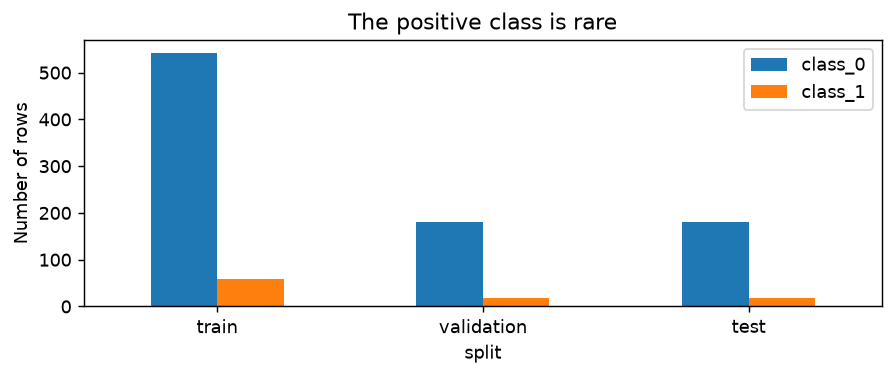

In [3]:
train_validation, test_index = train_test_split(np.arange(len(data)), test_size=.2, stratify=y, random_state=SEED)
train_index, validation_index = train_test_split(train_validation, test_size=.25, stratify=y[train_validation], random_state=SEED)
assert not (set(train_index) & set(validation_index) or set(train_index) & set(test_index) or set(validation_index) & set(test_index))
assert len(train_index) + len(validation_index) + len(test_index) == len(data)
rows = []
for name, index in [("train", train_index), ("validation", validation_index), ("test", test_index)]:
    rows.append({"split": name, "rows": len(index), "class_0": int((y[index] == 0).sum()), "class_1": int((y[index] == 1).sum())})
    pd.DataFrame({"original_csv_row": selected[index]}).to_csv(OUT / f"{name}_rows.csv", index=False)
table(pd.DataFrame(rows), "split_counts")
fig, ax = plt.subplots(figsize=(7, 3))
pd.DataFrame(rows).set_index("split")[["class_0", "class_1"]].plot.bar(ax=ax, rot=0)
ax.set(ylabel="Number of rows", title="The positive class is rare")
picture(fig, "class_balance")
real_train = features.iloc[train_index].reset_index(drop=True)
y_train, y_validation, y_test = y[train_index], y[validation_index], y[test_index]

## 3. Inspect the actual training inputs

Histograms show typical values and long tails. The correlation plot shows linear relationships between numeric columns; it is not proof of causation. All plots here use **training rows only**.

feature,count,mean,std,min,25%,50%,75%,max
Age,600.0,45.440000,11.655449,23.0,35.0,45.0,56.0,67.0
Experience,600.0,20.170000,11.591162,-3.0,10.0,20.0,30.0,41.0
Income,600.0,72.100000,47.826970,8.0,34.0,62.0,93.0,201.0
Family,600.0,2.393333,1.175127,1.0,1.0,2.0,4.0,4.0
CCAvg,600.0,1.923017,1.830019,0.0,0.6,1.4,2.5,8.9
Mortgage,600.0,60.836667,104.191585,0.0,0.0,0.0,105.5,601.0


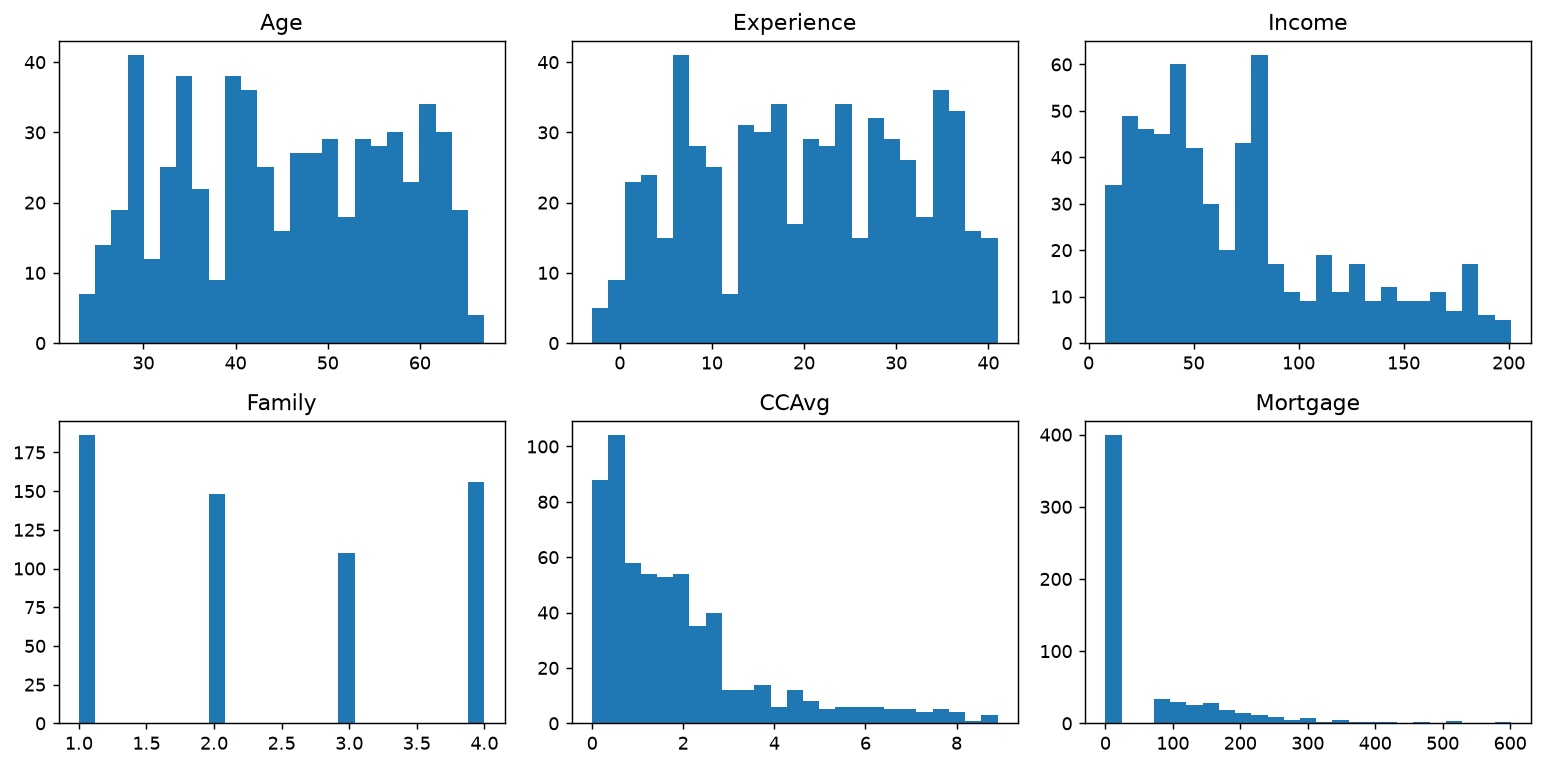

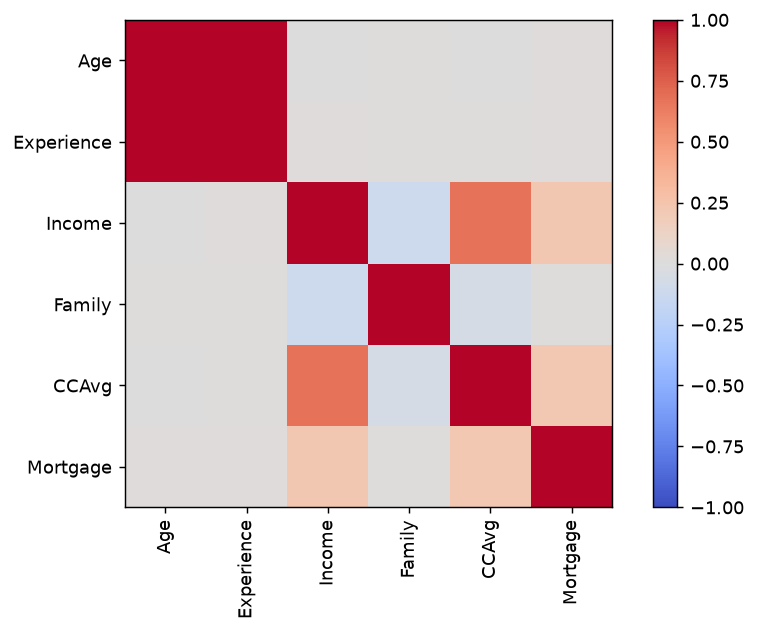

In [4]:
table(real_train[NUMERICAL].describe().T.reset_index().rename(columns={"index": "feature"}), "training_numeric_summary")
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, column in zip(axes.flat, NUMERICAL):
    ax.hist(real_train[column], bins=25); ax.set_title(column)
picture(fig, "input_histograms")
fig, ax = plt.subplots(figsize=(7, 5))
correlation = real_train[NUMERICAL].corr()
im = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(NUMERICAL)), NUMERICAL, rotation=90)
ax.set_yticks(range(len(NUMERICAL)), NUMERICAL); fig.colorbar(im, ax=ax)
picture(fig, "input_correlations")
correlation.to_csv(OUT / "input_correlations.csv")

## 4. Turn a real row into numbers the classical networks can read

Numeric columns: clip at **training** 1st/99th percentiles, standardize, then scale to [0, π]. Categories: **training-fitted one-hot encoding**. A category unseen during training becomes an all-zero group; we count those cases instead of fitting on validation/test data.

**This is not quantum state encoding.** These encoded real rows go to the classical discriminator or classifier. The quantum circuit receives independent random angles in the next step.

We disable numeric jitter in this deterministic lesson. The paper describes Gaussian jitter; see `PAPER_SETTINGS.md`.

In [5]:
pre = TabularPreprocessor(NUMERICAL, CATEGORICAL, noise_std=0)
x_train = pre.fit_transform(real_train).astype(np.float32)
fitted_statistics = copy.deepcopy((pre.q1, pre.q99, pre.mean, pre.std, pre.min_value, pre.max_value))
x_validation = pre.transform(features.iloc[validation_index]).astype(np.float32)
x_test = pre.transform(features.iloc[test_index]).astype(np.float32)
assert fitted_statistics == (pre.q1, pre.q99, pre.mean, pre.std, pre.min_value, pre.max_value), "Held-out transforms changed the encoder!"
assert np.isfinite(x_train).all() and np.isfinite(x_validation).all() and np.isfinite(x_test).all()
assert x_train[:, :len(NUMERICAL)].min() >= -1e-6
assert x_train[:, :len(NUMERICAL)].max() <= np.pi + 1e-6
table(pd.DataFrame([{"feature": c, "train_p01": pre.q1[c], "train_p99": pre.q99[c], "train_clipped_mean": pre.mean[c], "train_clipped_std": pre.std[c]} for c in NUMERICAL]), "fitted_numeric_parameters")
conditions = np.eye(2, dtype=np.float32)[y_train]
print("Encoded train / validation / test:", x_train.shape, x_validation.shape, x_test.shape)
print("One-hot class conditions:", conditions.shape)
table(pd.DataFrame({"raw_column": NUMERICAL, "raw_value": real_train.iloc[0][NUMERICAL].to_numpy(),
                    "encoded_value": x_train[0, :len(NUMERICAL)]}), "one_row_numeric_encoding")
table(pd.DataFrame({"encoded_column": pre.output_columns[:20], "first_row_value": x_train[0, :20]}))
unknown = []
offset = len(NUMERICAL)
for column, categories in zip(CATEGORICAL, pre.encoder.categories_):
    width = len(categories)
    np.testing.assert_allclose(x_train[:, offset:offset+width].sum(1), 1)
    unknown.append({"feature": column, "training_categories": width,
                    "validation_unknown_fraction": float((~features.iloc[validation_index][column].isin(categories)).mean()),
                    "test_unknown_fraction": float((~features.iloc[test_index][column].isin(categories)).mean())})
    offset += width
assert offset == x_train.shape[1]
table(pd.DataFrame(unknown), "encoding_checks")

feature,train_p01,train_p99,train_clipped_mean,train_clipped_std
Age,24.0,65.000,45.436667,11.621789
Experience,-1.0,40.010,20.173433,11.538656
Income,9.0,190.020,72.028533,47.597108
Family,1.0,4.000,2.393333,1.174147
CCAvg,0.0,8.001,1.918527,1.812644
Mortgage,0.0,458.090,60.090900,100.842790


Encoded train / validation / test: (600, 289) (200, 289) (200, 289)
One-hot class conditions: (600, 2)


raw_column,raw_value,encoded_value
Age,65.0,3.141593
Experience,41.0,3.141593
Income,170.0,2.794147
Family,4.0,3.141593
CCAvg,6.1,2.395165
Mortgage,0.0,0.000000


encoded_column,first_row_value
Age,3.141593
Experience,3.141593
Income,2.794147
Family,3.141593
CCAvg,2.395165
Mortgage,0.000000
ZIP Code_90007,0.000000
ZIP Code_90009,0.000000
ZIP Code_90011,0.000000
ZIP Code_90024,0.000000


feature,training_categories,validation_unknown_fraction,test_unknown_fraction
ZIP Code,272,0.285,0.29
Education,3,0.000,0.00
SecuritiesAccount,2,0.000,0.00
CDAccount,2,0.000,0.00
Online,2,0.000,0.00
CreditCard,2,0.000,0.00


## 5. Build the actual shared QTabGAN model

We keep the original paper-based circuit: eight qubits, H initialization, random RY encoding, trainable RY/RZ blocks and circular CNOTs. D(x,y) is the explicit conditional interpretation of paper §3.2. Concatenating y at its input is our stated wiring assumption.

Small classical widths and five epochs make this a lesson, not a competitive model. Analytic simulator gradients are used instead of finite-shot parameter-shift training. No quantum hardware is contacted.

In [6]:
cfg = QTabGANConfig(n_qubits=8, n_layers=2, ansatz="paper", condition_discriminator=True,
                    mapper_hidden=(32, 32), discriminator_hidden=(32, 16),
                    batch_size=64, epochs=1, seed=SEED, classical_init_seed=42042)
model = QTabGAN(x_train.shape[1], 2, cfg)
initial_angles = model.quantum_generator.weights.detach().clone()
table(pd.DataFrame([{"component": name, "parameters": sum(p.numel() for p in module.parameters())}
                    for name, module in [("quantum circuit", model.quantum_generator), ("mapper", model.mapper), ("discriminator", model.discriminator)]]), "parameter_counts")
print(model.mapper)
print(model.discriminator)
print("The model creates features. A separate classifier will predict the loan label later.")

component,parameters
quantum circuit,32
mapper,18881
discriminator,9889


ClassicalMapper(
  (model): MLP(
    (network): Sequential(
      (0): Linear(in_features=258, out_features=32, bias=True)
      (1): ReLU()
      (2): Linear(in_features=32, out_features=32, bias=True)
      (3): ReLU()
      (4): Linear(in_features=32, out_features=289, bias=True)
    )
  )
)
Discriminator(
  (model): MLP(
    (network): Sequential(
      (0): Linear(in_features=291, out_features=32, bias=True)
      (1): ReLU()
      (2): Linear(in_features=32, out_features=16, bias=True)
      (3): ReLU()
      (4): Linear(in_features=16, out_features=1, bias=True)
    )
  )
)
The model creates features. A separate classifier will predict the loan label later.


## 6. Inspect the quantum circuit's input and output

Each generated customer starts with eight random angles. The circuit produces **256 probabilities**, one per bitstring. They must be finite, nonnegative and sum to one.

The mapper receives that probability vector plus a requested class—not a real customer's encoded features. Gate angles are trainable parameters, while the random input angles supply variation.

angle_q0,angle_q1,angle_q2,angle_q3,angle_q4,angle_q5,angle_q6,angle_q7
2.914615,1.246972,2.509286,0.971873,2.928228,1.915372,0.353998,2.166284
0.535177,1.900341,1.812980,1.386218,1.534390,0.140633,2.091892,0.607377
1.986275,0.143760,1.924864,0.374374,0.301892,2.925079,2.133156,1.689852


Probability sums: [0.99999964 0.9999998  0.9999999  0.99999964 0.9999997  0.99999976
 0.99999964 0.9999999 ]


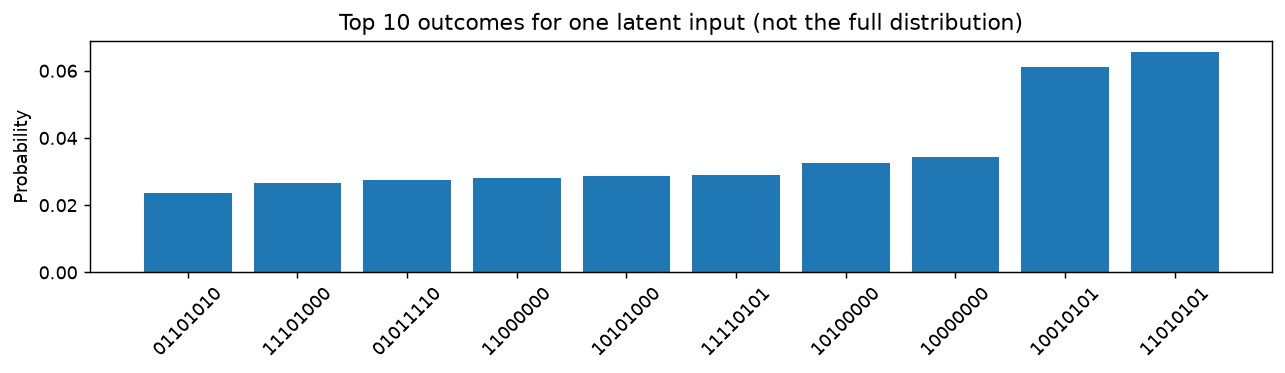

QTabGAN_step_by_step.ipynb:cell_1:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


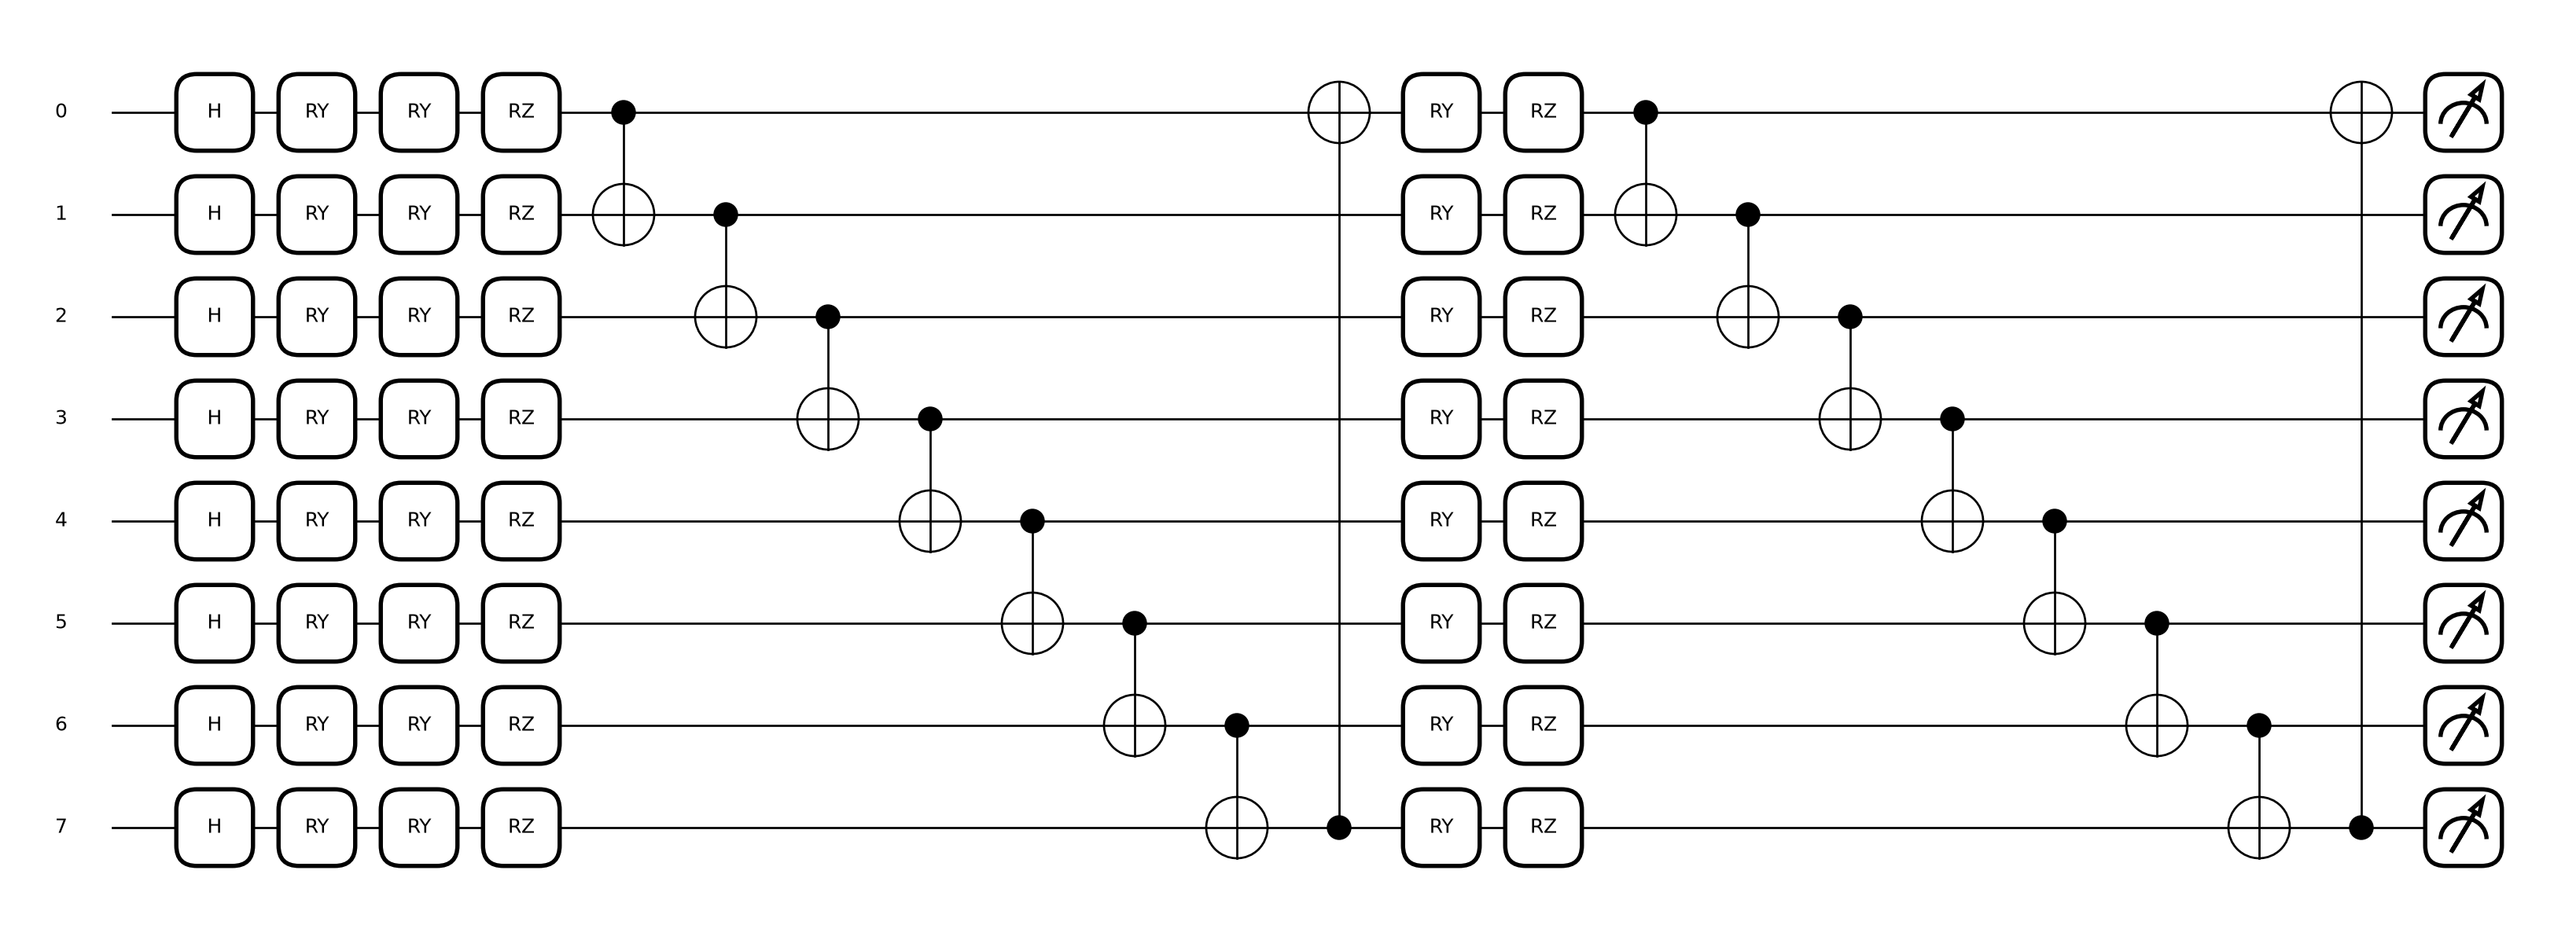

In [7]:
with evaluation_rng(SEED + 100):
    fixed_noise = torch.rand(8, cfg.n_qubits) * np.pi
    with torch.no_grad(): probabilities = model.quantum_generator(fixed_noise)
assert probabilities.shape == (8, 256)
assert torch.isfinite(probabilities).all() and (probabilities >= 0).all()
torch.testing.assert_close(probabilities.sum(1), torch.ones(8))
table(pd.DataFrame(fixed_noise.numpy(), columns=[f"angle_q{i}" for i in range(8)]).head(3), "latent_angles")
print("Probability sums:", probabilities.sum(1).numpy())
p = probabilities[0].numpy(); top = np.argsort(p)[-10:]
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar([format(int(i), "08b") for i in top], p[top]); ax.tick_params(axis="x", rotation=45)
ax.set(ylabel="Probability", title="Top 10 outcomes for one latent input (not the full distribution)")
picture(fig, "quantum_probabilities")
fig, _ = qml.draw_mpl(model.quantum_generator.circuit, decimals=None)(fixed_noise[0], model.quantum_generator.weights)
picture(fig, "training_circuit")
(OUT / "training_circuit.txt").write_text(qml.draw(model.quantum_generator.circuit)(fixed_noise[0], model.quantum_generator.weights))

### Check what happens inside the classical networks

Follow shapes and ranges through every Linear/ReLU layer. ReLU replaces negative hidden values with zero; the final mapper layer is linear and can still produce negative or out-of-range features. These are checks of numerical behavior, not evidence of good data.


In [8]:
activation_rows = []
with torch.no_grad():
    mapper_input = torch.cat([probabilities, torch.tensor(conditions[:8])], dim=1)
    discriminator_input = torch.cat([torch.tensor(x_train[:8]), torch.tensor(conditions[:8])], dim=1)
    for name, network, value in [("mapper", model.mapper.model.network, mapper_input),
                                  ("discriminator", model.discriminator.model.network, discriminator_input)]:
        for number, layer in enumerate(network):
            value = layer(value)
            assert torch.isfinite(value).all()
            activation_rows.append({"network": name, "layer": number, "operation": type(layer).__name__,
                                    "shape": str(tuple(value.shape)), "min": float(value.min()),
                                    "max": float(value.max()), "zero_fraction": float((value == 0).float().mean())})
table(pd.DataFrame(activation_rows), "internal_layer_checks")


network,layer,operation,shape,min,max,zero_fraction
mapper,0,Linear,"(8, 32)",-0.092039,0.081200,0.000000
mapper,1,ReLU,"(8, 32)",0.000000,0.081200,0.667969
mapper,2,Linear,"(8, 32)",-0.171408,0.176763,0.000000
mapper,3,ReLU,"(8, 32)",0.000000,0.176763,0.406250
mapper,4,Linear,"(8, 289)",-0.236432,0.242922,0.000000
discriminator,0,Linear,"(8, 32)",-0.646386,0.562986,0.000000
discriminator,1,ReLU,"(8, 32)",0.000000,0.562986,0.449219
discriminator,2,Linear,"(8, 16)",-0.302964,0.283382,0.000000
discriminator,3,ReLU,"(8, 16)",0.000000,0.283382,0.539062
discriminator,4,Linear,"(8, 1)",-0.073761,-0.020858,0.000000


## 7. Check Hadamard physics with explicit numbers

H turns |0⟩ into equal amplitudes for 0 and 1; probabilities are squared magnitudes. H twice restores the original state. Complex phases matter because later gates can convert them into probability differences.

Our original circuit's last RZ gates are followed only by CNOTs before ordinary measurement, so their phases cannot affect the output probabilities. The repository's optional `paper_readout` extension adds final H gates to make those phases observable; this lesson keeps the original circuit.

In [9]:
H = np.array([[1., 1.], [1., -1.]]) / np.sqrt(2)
zero = np.array([1., 0.])
plus = H @ zero
print("H|0> amplitudes:", plus)
print("Measured probabilities:", np.abs(plus)**2)
print("H twice:", H @ plus)
np.testing.assert_allclose(H @ H, np.eye(2), atol=1e-12)

H|0> amplitudes: [0.70710678 0.70710678]
Measured probabilities: [0.5 0.5]
H twice: [1.00000000e+00 2.23711432e-17]


## 8. Inspect one adversarial calculation before taking optimizer steps

The discriminator's *logits* are raw real/fake scores; sigmoid converts them to probabilities. Its loss averages real-target-1 and fake-target-0 BCE losses. The generator's loss assigns target 1 to generated rows, asking it to fool the discriminator.

`backward()` calculates gradients. Adam would use those gradients to adjust weights. This cell takes **no optimizer step**; it just verifies the path through the quantum circuit. Zero final-RZ gradients are expected for the original circuit; a nonzero gradient elsewhere is not proof of good synthetic data.

Real/fake batch shapes: (8, 289) (8, 289)
Discriminator sees features + 2 class columns: 291
Mean D(real), D(fake): 0.48842498660087585 0.4754676818847656
D loss: 0.6809279918670654 G loss: 0.7434566617012024 Quantum gradient norm: 3.2627868e-05


real_logit,fake_logit,D_loss_contribution,G_loss_contribution
-0.039008,-0.095631,0.679658,0.742105
-0.020858,-0.095657,0.675046,0.742119
-0.063302,-0.099066,0.685070,0.743906
-0.027702,-0.099032,0.675975,0.743889
-0.073761,-0.099006,0.687788,0.743875
-0.047823,-0.099182,0.681065,0.743967
-0.038306,-0.099086,0.678657,0.743917
-0.059733,-0.099006,0.684164,0.743875


The mean of each loss-contribution column matches the printed BCE loss.


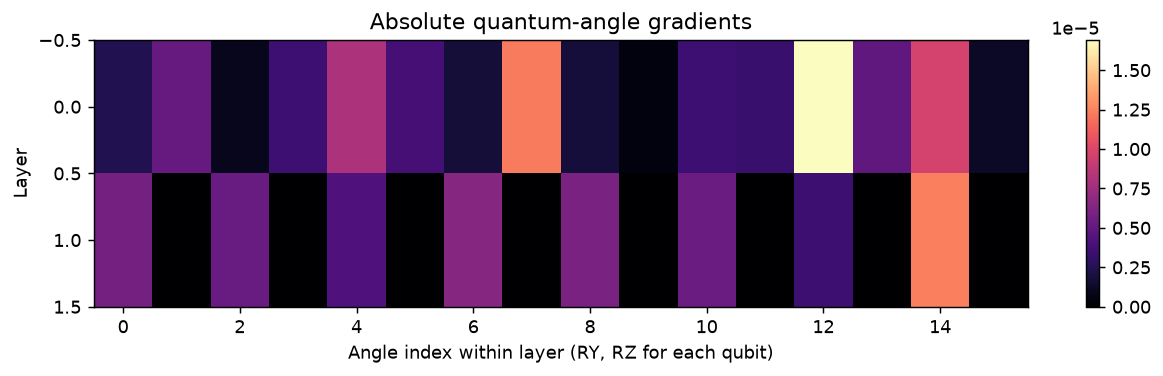

In [10]:
condition_batch = torch.tensor(conditions[:8])
real_batch = torch.tensor(x_train[:8])
model.zero_grad(set_to_none=True)
quantum_batch = model.quantum_generator(fixed_noise)
fake_batch = model.mapper(quantum_batch, condition_batch)
real_logits = model.discriminate(real_batch, condition_batch)
fake_logits = model.discriminate(fake_batch.detach(), condition_batch)
criterion = torch.nn.BCEWithLogitsLoss()
d_loss = (criterion(real_logits, torch.ones_like(real_logits)) + criterion(fake_logits, torch.zeros_like(fake_logits))) / 2
g_logits = model.discriminate(fake_batch, condition_batch)
g_loss = criterion(g_logits, torch.ones_like(g_logits))
g_loss.backward()
angle_gradient = model.quantum_generator.weights.grad.detach().numpy().copy()
assert np.isfinite(angle_gradient).all() and np.linalg.norm(angle_gradient) > 0
print("Real/fake batch shapes:", tuple(real_batch.shape), tuple(fake_batch.shape))
print("Discriminator sees features + 2 class columns:", model.discriminator.model.network[0].in_features)
print("Mean D(real), D(fake):", torch.sigmoid(real_logits).mean().item(), torch.sigmoid(fake_logits).mean().item())
print("D loss:", d_loss.item(), "G loss:", g_loss.item(), "Quantum gradient norm:", np.linalg.norm(angle_gradient))
manual_d = (np.logaddexp(0, -real_logits.detach().numpy()) + np.logaddexp(0, fake_logits.detach().numpy())) / 2
manual_g = np.logaddexp(0, -g_logits.detach().numpy())
np.testing.assert_allclose(manual_d.mean(), d_loss.item(), rtol=1e-6)
np.testing.assert_allclose(manual_g.mean(), g_loss.item(), rtol=1e-6)
table(pd.DataFrame({"real_logit": real_logits.detach().numpy().ravel(), "fake_logit": fake_logits.detach().numpy().ravel(),
                    "D_loss_contribution": manual_d.ravel(), "G_loss_contribution": manual_g.ravel()}), "one_batch_losses")
print("The mean of each loss-contribution column matches the printed BCE loss.")
fig, ax = plt.subplots(figsize=(10, 3))
im = ax.imshow(np.abs(angle_gradient.reshape(cfg.n_layers, -1)), aspect="auto", cmap="magma")
ax.set(xlabel="Angle index within layer (RY, RZ for each qubit)", ylabel="Layer", title="Absolute quantum-angle gradients")
fig.colorbar(im, ax=ax); picture(fig, "initial_quantum_gradients")
model.zero_grad(set_to_none=True)

## 9. Establish a real-data reference—using validation only

Train a 100-tree Random Forest on **real training rows and their real labels**. Evaluate on validation rows. This tells us what the same evaluator can do without generated data.

Accuracy alone can reward predicting the majority class. Macro F1 treats both classes equally; AUROC describes ranking; average precision emphasizes positive-case retrieval. **Brier MSE** measures how close predicted probabilities are to binary labels (lower is better). This is an evaluation metric, not the GAN's training loss.

Numerically, Brier MSE is `mean((predicted_positive_probability - true_binary_label)**2)`.


In [11]:
teacher = classifier(x_train, y_train, SEED)
real_validation, _, _ = score(teacher, x_validation, y_validation)
majority_class = int(np.bincount(y_train).argmax())
validation_majority_accuracy = float((y_validation == majority_class).mean())
print("Majority-class validation accuracy:", validation_majority_accuracy)
table(pd.DataFrame([{"model": "real-trained reference", **real_validation}]), "real_validation")

Majority-class validation accuracy: 0.905


model,accuracy,macro_f1,auroc,average_precision,brier_mse
real-trained reference,0.945,0.781551,0.956673,0.949598,0.033017


## 10. Train a short GAN and log what changes

Each epoch uses the shared `QTabGAN.fit()` implementation. Adam performs one discriminator update and one generator update per minibatch; each learning rate is 0.0002. Successive `fit()` calls retain Adam's state.

After each epoch, generate training-sized synthetic data, decode it, fit a Random Forest on those synthetic rows and their **requested labels**, and evaluate on validation rows. Requested labels are not proof that generated features match the label.

Evaluation restores the training RNG afterwards. We save a checkpoint in memory when validation macro F1 improves. Test rows are not scored here.

`feature_mean_mse` compares encoded **column means**. It can be small even if every generated customer is the same. We never use row-by-row MSE between unrelated real and synthetic people.

In [12]:
records = []
best_validation_f1 = -1
best_epoch = None
set_seed(SEED + 20000)
for epoch in range(1, EPOCHS + 1):
    history = model.fit(x_train, conditions, verbose=False)
    with evaluation_rng(SEED + 10000):
        generated = model.generate(conditions)
        decoded = pre.inverse_transform(generated)
        encoded_fake = pre.transform(decoded).astype(np.float32)
        synthetic_classifier = classifier(encoded_fake, y_train, SEED)
        validation_metrics, _, _ = score(synthetic_classifier, x_validation, y_validation)
        numeric_check, category_check = diversity(real_train, decoded, y_train, NUMERICAL, CATEGORICAL)
        mean_mse = float(np.mean((x_train[:, :len(NUMERICAL)].mean(0) - encoded_fake[:, :len(NUMERICAL)].mean(0))**2))
    record = {"epoch": epoch, **{key: values[-1] for key, values in history.items()},
              **{f"validation_{key}": value for key, value in validation_metrics.items()},
              "feature_mean_mse": mean_mse,
              "within_class_std_ratio": float(numeric_check.minimum_within_class_std_ratio.mean()),
              "category_coverage": float(category_check.coverage.mean())}
    records.append(record)
    print(f"Epoch {epoch}: G={record['generator_loss']:.4f}, D={record['discriminator_loss']:.4f}, validation F1={validation_metrics['macro_f1']:.3f}")
    if validation_metrics["macro_f1"] > best_validation_f1:
        best_validation_f1 = validation_metrics["macro_f1"]
        best_epoch = epoch
        best_weights = copy.deepcopy(model.state_dict())
        best_classifier = copy.deepcopy(synthetic_classifier)
        best_fake = decoded.copy()
log = pd.DataFrame(records)
log.to_csv(OUT / "training_log.csv", index=False)
table(log.round(6))
print("Selected epoch:", best_epoch, "using validation macro F1 only.")

Epoch 1: G=0.7496, D=0.6794, validation F1=0.483
Epoch 2: G=0.7557, D=0.6707, validation F1=0.356
Epoch 3: G=0.7601, D=0.6626, validation F1=0.335
Epoch 4: G=0.7625, D=0.6549, validation F1=0.335
Epoch 5: G=0.7652, D=0.6461, validation F1=0.335


epoch,generator_loss,discriminator_loss,quantum_gradient_norm,validation_accuracy,validation_macro_f1,validation_auroc,validation_average_precision,validation_brier_mse,feature_mean_mse,within_class_std_ratio,category_coverage
1,0.749618,0.679405,0.000017,0.835,0.483366,0.524716,0.102478,0.213682,1.399585,0.000544,0.389502
2,0.755724,0.670738,0.000011,0.400,0.356499,0.537220,0.103894,0.222741,1.391296,0.000549,0.389502
3,0.760104,0.662639,0.000010,0.370,0.334812,0.516720,0.101522,0.270426,1.384143,0.000548,0.389502
4,0.762465,0.654930,0.000011,0.370,0.334812,0.535330,0.103894,0.292551,1.380412,0.000545,0.389502
5,0.765211,0.646050,0.000010,0.370,0.334812,0.518465,0.101114,0.275023,1.379178,0.000538,0.389502


Selected epoch: 1 using validation macro F1 only.


## 11. Plot learning, calibration and diversity

Generator/discriminator losses measure the competition, not classifier accuracy. Gradients confirm a signal reaches quantum parameters. Validation curves show downstream usefulness.

A within-class standard-deviation ratio near zero means nearly identical generated values within each label. Category coverage tells us how many training categories appear in generated data. Neither a nice loss curve nor a small feature-mean MSE is enough to establish success.

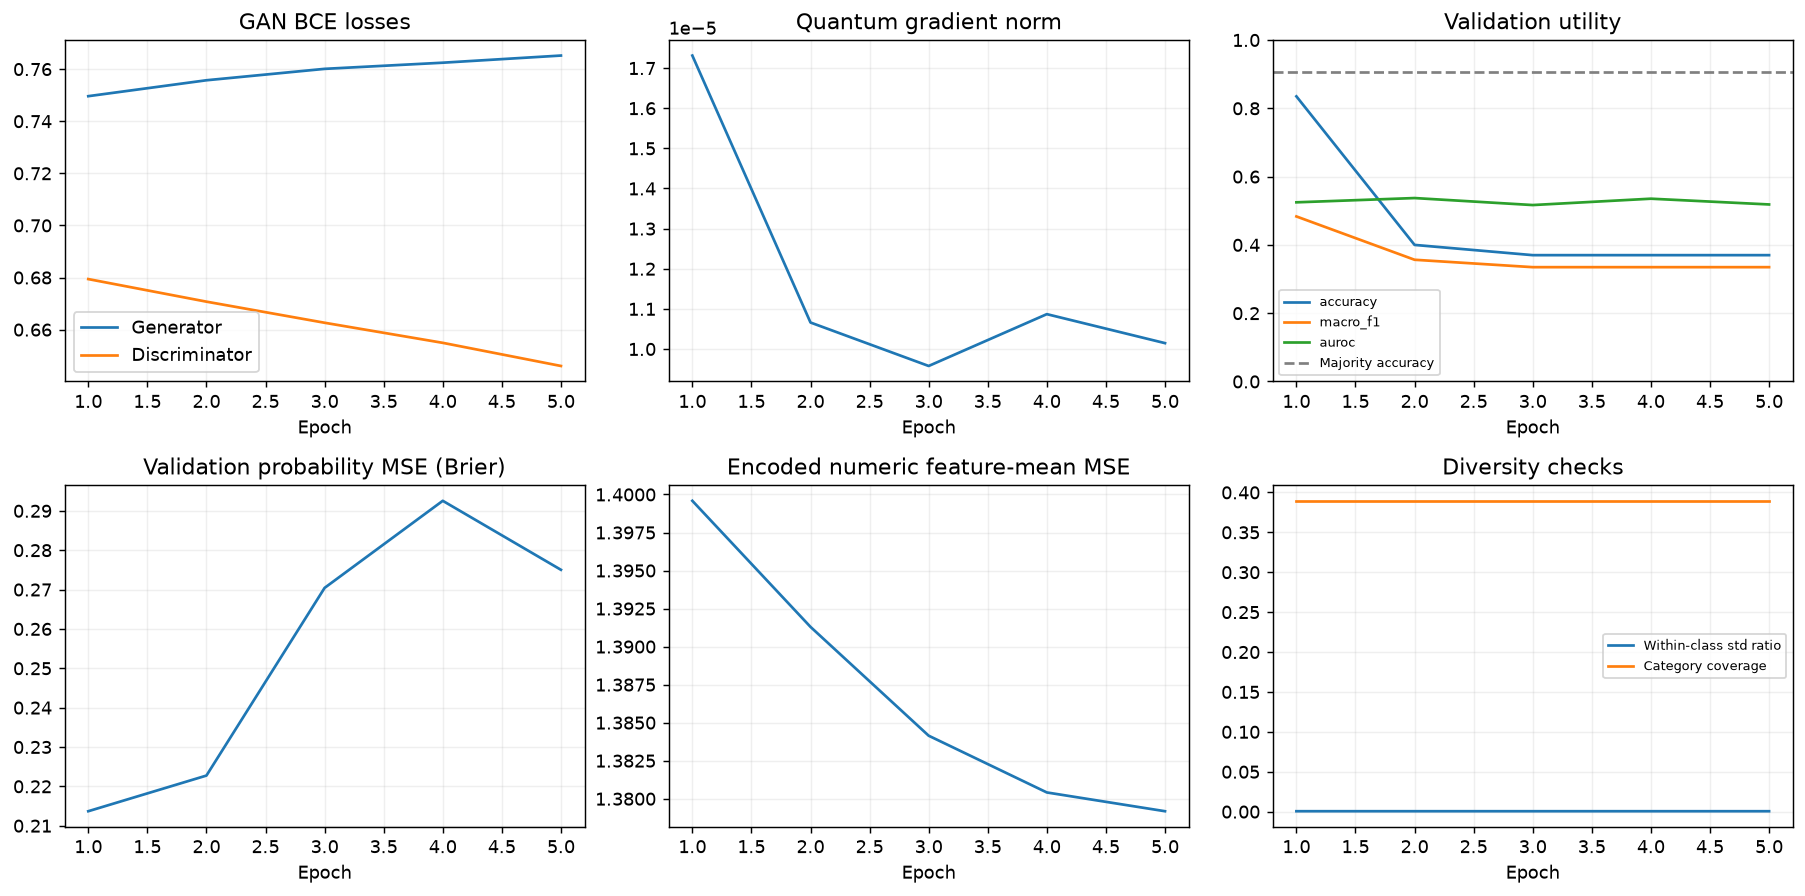

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes[0,0].plot(log.epoch, log.generator_loss, label="Generator"); axes[0,0].plot(log.epoch, log.discriminator_loss, label="Discriminator")
axes[0,0].set_title("GAN BCE losses"); axes[0,0].legend()
axes[0,1].plot(log.epoch, log.quantum_gradient_norm); axes[0,1].set_title("Quantum gradient norm")
for metric in ["accuracy", "macro_f1", "auroc"]:
    axes[0,2].plot(log.epoch, log[f"validation_{metric}"], label=metric)
axes[0,2].axhline(validation_majority_accuracy, color="gray", linestyle="--", label="Majority accuracy")
axes[0,2].set(ylim=(0,1), title="Validation utility"); axes[0,2].legend(fontsize=7)
axes[1,0].plot(log.epoch, log.validation_brier_mse); axes[1,0].set_title("Validation probability MSE (Brier)")
axes[1,1].plot(log.epoch, log.feature_mean_mse); axes[1,1].set_title("Encoded numeric feature-mean MSE")
axes[1,2].plot(log.epoch, log.within_class_std_ratio, label="Within-class std ratio")
axes[1,2].plot(log.epoch, log.category_coverage, label="Category coverage")
axes[1,2].set_title("Diversity checks"); axes[1,2].legend(fontsize=7)
for ax in axes.flat: ax.set_xlabel("Epoch"); ax.grid(alpha=.2)
picture(fig, "learning_dashboard")

## 12. Freeze the selected checkpoint, then test

Only now do we score test rows. We compare a classifier trained on real rows against the classifier trained on the selected synthetic rows. The GAN is not the loan-label predictor.

Confusion matrices use rows=true class and columns=predicted class. AUROC and precision–recall curves come from the Random Forest's probabilities, not from the GAN discriminator. A five-epoch demonstration is expected to be weak; the purpose is to make the chain inspectable.

Selected quantum-angle update: max absolute change = 0.0019316673278808594
All parameters finite: True


model,accuracy,macro_f1,auroc,average_precision,brier_mse
real-trained reference,0.970,0.898098,0.988805,0.933093,0.031007
synthetic-trained classifier,0.805,0.445983,0.528787,0.110521,0.223847


Majority-class test accuracy: 0.905


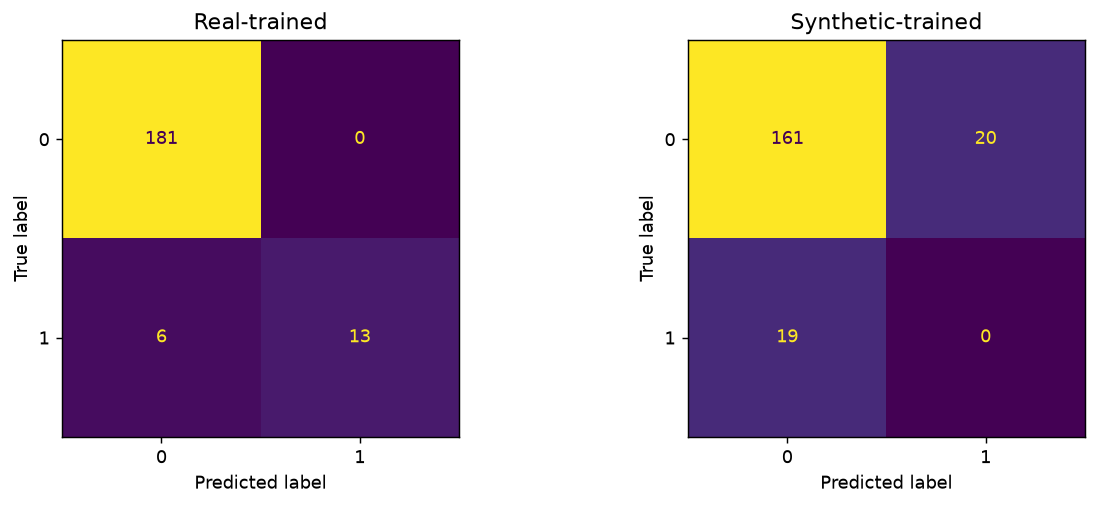

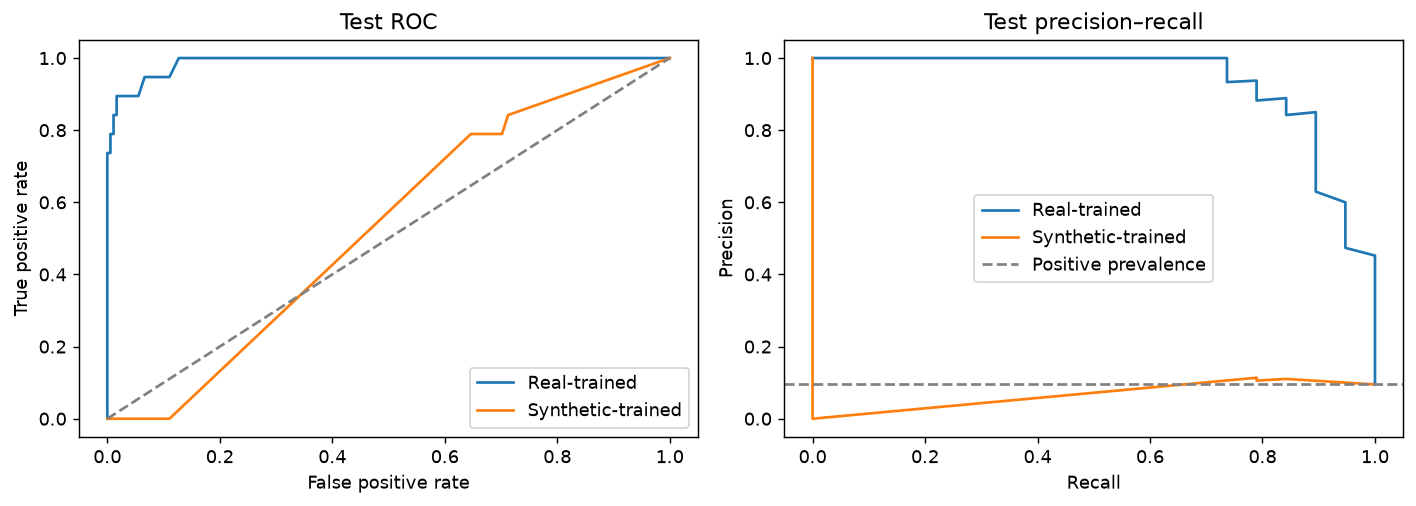

In [14]:
model.load_state_dict(best_weights)
angle_change = model.quantum_generator.weights.detach() - initial_angles
print("Selected quantum-angle update: max absolute change =", angle_change.abs().max().item())
print("All parameters finite:", all(torch.isfinite(p).all().item() for p in model.parameters()))
assert angle_change.abs().max().item() > 0
real_test, real_prediction, real_probability = score(teacher, x_test, y_test)
fake_test, fake_prediction, fake_probability = score(best_classifier, x_test, y_test)
final_scores = pd.DataFrame([{"model": "real-trained reference", **real_test}, {"model": "synthetic-trained classifier", **fake_test}])
table(final_scores, "final_test_scores")
print("Majority-class test accuracy:", float((y_test == majority_class).mean()))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, prediction, title in [(axes[0], real_prediction, "Real-trained"), (axes[1], fake_prediction, "Synthetic-trained")]:
    ConfusionMatrixDisplay.from_predictions(y_test, prediction, labels=[0,1], ax=ax, colorbar=False)
    ax.set_title(title)
picture(fig, "test_confusion_matrices")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, probability in [("Real-trained", real_probability), ("Synthetic-trained", fake_probability)]:
    fpr, tpr, _ = roc_curve(y_test, probability)
    precision, recall, _ = precision_recall_curve(y_test, probability)
    axes[0].plot(fpr, tpr, label=name); axes[1].plot(recall, precision, label=name)
axes[0].plot([0,1], [0,1], "--", color="gray")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="Test ROC")
axes[1].axhline((y_test == 1).mean(), linestyle="--", color="gray", label="Positive prevalence")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Test precision–recall")
for ax in axes: ax.legend()
picture(fig, "test_auc_curves")
predictions = pd.DataFrame({"original_csv_row": selected[test_index], "truth": y_test,
                            "synthetic_classifier_prediction": fake_prediction,
                            "synthetic_classifier_probability": fake_probability,
                            "real_classifier_prediction": real_prediction, "real_classifier_probability": real_probability})
predictions.to_csv(OUT / "test_predictions.csv", index=False)

## 13. Check the generated rows themselves

Compare distributions rather than pairing unrelated customers. Raw decoded values are important: re-encoding clips numeric values and can hide extreme outputs. The mapper has a linear output as in the paper, so invalid or unrealistic generated values are possible.

Histograms reveal narrow peaks; correlation differences show lost relationships. Constant synthetic columns have undefined correlations and appear blank rather than being called a match.

First generated rows (feature values only):


Age,Experience,Income,Family,CCAvg,Mortgage,ZIP Code,Education,SecuritiesAccount,CDAccount,Online,CreditCard
26.085261,0.030991,9.596330,1.044959,0.200767,-22.717990,92069,2,0,1,1,0
26.081928,0.017699,9.621407,1.044031,0.200219,-22.737226,92069,2,0,1,1,0
25.958277,0.070368,9.551400,1.038779,0.214917,-23.237469,92069,2,0,1,1,0
25.981912,0.054943,9.650879,1.040163,0.213034,-23.039923,92069,2,0,1,1,0
25.964669,0.057882,9.558609,1.038066,0.215799,-23.202097,92069,2,0,1,1,0
25.964729,0.067790,9.554082,1.039382,0.212101,-23.144363,92069,2,0,1,1,0


feature,real_mean,fake_mean,real_std,fake_std,minimum_within_class_std_ratio,outside_train_range_fraction
Age,45.440000,25.976869,11.645732,0.034596,0.000551,0.0
Experience,20.170000,0.065354,11.581498,0.016374,0.000466,0.0
Income,72.100000,9.576320,47.787097,0.036927,0.000700,0.0
Family,2.393333,1.039885,1.174147,0.001659,0.000520,0.0
CCAvg,1.923017,0.213961,1.828493,0.004732,0.000656,0.0
Mortgage,60.836667,-23.131532,104.104723,0.166971,0.000370,1.0


feature,real_categories,fake_categories,coverage
ZIP Code,272,1,0.003676
Education,3,1,0.333333
SecuritiesAccount,2,1,0.500000
CDAccount,2,1,0.500000
Online,2,1,0.500000
CreditCard,2,1,0.500000


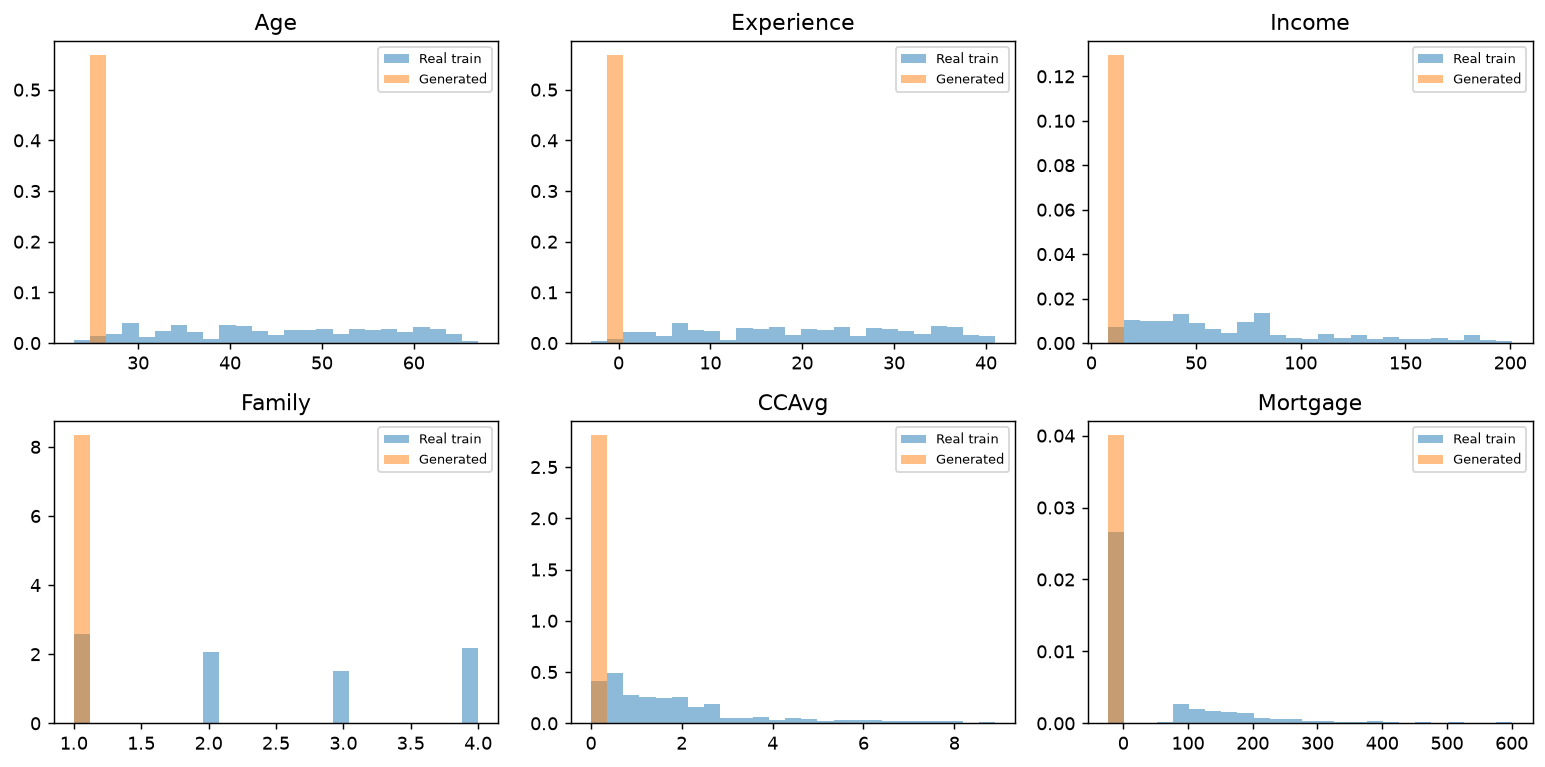

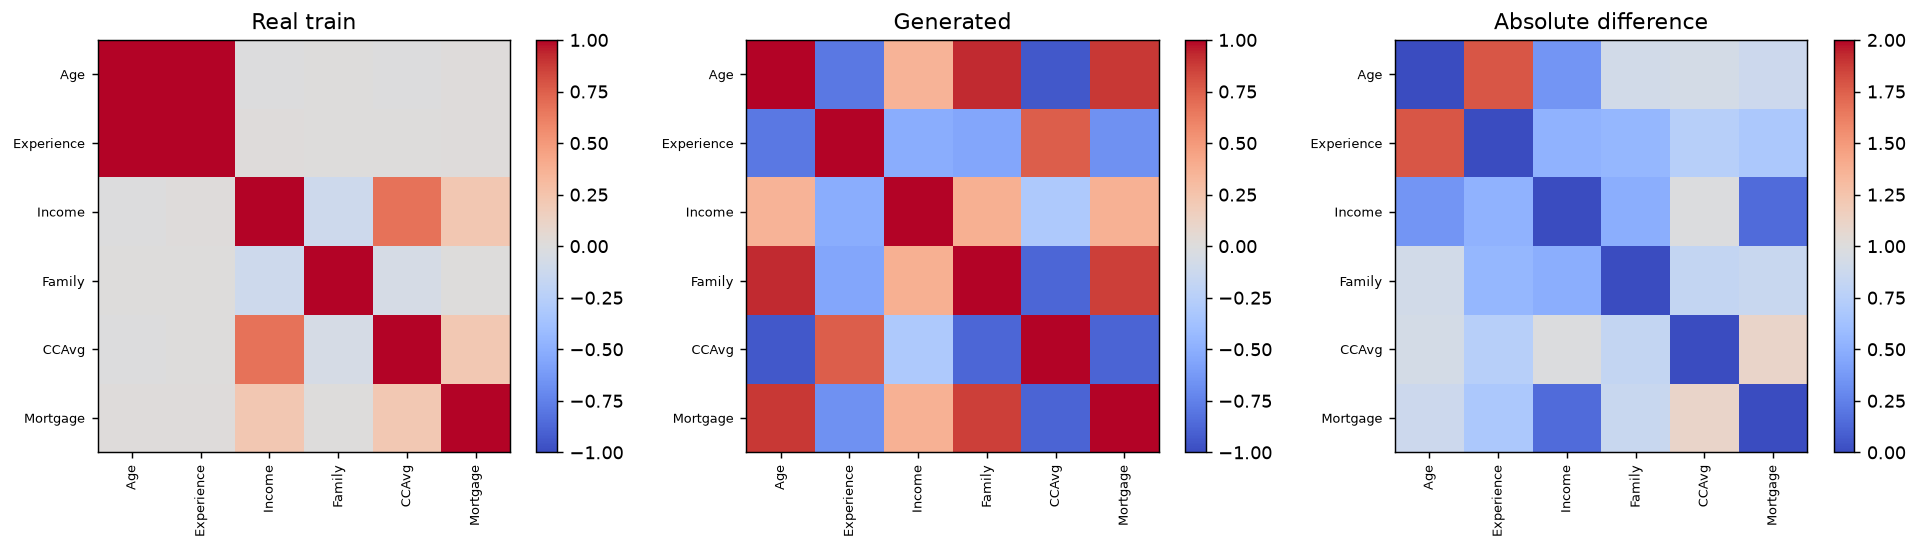

In [15]:
print("First generated rows (feature values only):")
table(best_fake.head(6))
numeric_check, category_check = diversity(real_train, best_fake, y_train, NUMERICAL, CATEGORICAL)
table(numeric_check, "raw_numeric_diagnostics")
table(category_check, "category_coverage")
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, column in zip(axes.flat, NUMERICAL):
    bins = np.histogram_bin_edges(np.r_[real_train[column], best_fake[column]], bins=25)
    ax.hist(real_train[column], bins=bins, density=True, alpha=.5, label="Real train")
    ax.hist(best_fake[column], bins=bins, density=True, alpha=.5, label="Generated")
    ax.set_title(column); ax.legend(fontsize=7)
picture(fig, "generated_vs_real")
real_corr = real_train[NUMERICAL].corr(); fake_corr = best_fake[NUMERICAL].corr()
real_corr.to_csv(OUT / "real_correlations.csv"); fake_corr.to_csv(OUT / "generated_correlations.csv")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, matrix, title in [(axes[0], real_corr, "Real train"), (axes[1], fake_corr, "Generated"),
                           (axes[2], (real_corr-fake_corr).abs(), "Absolute difference")]:
    im = ax.imshow(matrix, cmap="coolwarm", vmin=-1 if title != "Absolute difference" else 0, vmax=1 if title != "Absolute difference" else 2)
    ax.set_xticks(range(len(NUMERICAL)), NUMERICAL, rotation=90, fontsize=7)
    ax.set_yticks(range(len(NUMERICAL)), NUMERICAL, fontsize=7); ax.set_title(title); fig.colorbar(im, ax=ax)
picture(fig, "correlation_checks")
best_fake.assign(**{TARGET: np.asarray(label_names)[y_train]}).to_csv(OUT / "synthetic_demo.csv", index=False)

## 14. Follow one final prediction

During prediction, a real row goes through the fitted encoder and the selected Random Forest. The quantum generator is **not called**. It was used earlier to create the classifier's training dataset.

We demonstrate with one already-tested row; this is not an extra independent test. The class probability is the classifier's estimate, not a validated lending decision or the GAN discriminator's probability.

In [16]:
row = features.iloc[[test_index[0]]]
encoded_row = pre.transform(row).astype(np.float32)
probability = best_classifier.predict_proba(encoded_row)[0, list(best_classifier.classes_).index(1)]
predicted = int(best_classifier.predict(encoded_row)[0])
np.testing.assert_allclose(probability, fake_probability[0])
print("Original CSV row:", int(selected[test_index[0]]))
table(row)
print("Encoded shape:", encoded_row.shape)
print("Classifier probability of class 1:", float(probability))
print("Predicted original label:", label_names[predicted], "Observed original label:", label_names[y_test[0]])

Original CSV row: 4648


Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,SecuritiesAccount,CDAccount,Online,CreditCard
37,11,75,94704,3,0.9,2,0,0,0,1,0


Encoded shape: (1, 289)
Classifier probability of class 1: 0.49
Predicted original label: 0 Observed original label: 0


## 15. Save the audit trail and distinguish the CTGAN comparison

Our loss/utility numbers describe this small demonstration only. The retained CTGAN benchmark, if present, used a different data budget and protocol; it is shown for orientation, not directly compared with this notebook's scores.

SDV CTGAN is an external classical generator implementation. The actual matched full-data runner is `scripts/matched_ctgan.py`; its losses are not the same objective as this QTabGAN BCE loss. A valid comparison requires matched raw split rows and the same evaluator.

In [17]:
source_files = [ROOT / "qtabgan" / name for name in ["model.py", "config.py", "quantum_generator.py", "networks.py", "preprocessing.py"]]
source_files += [HERE / "helpers.py"]
notebook_source = json.loads((HERE / "QTabGAN_step_by_step.ipynb").read_text())
notebook_source_digest = hashlib.sha256(json.dumps([c["source"] for c in notebook_source["cells"]]).encode()).hexdigest()
manifest = {"purpose": "Teaching demonstration, not benchmark reproduction", "seed": SEED,
            "full_csv_rows": len(raw), "selected_rows": len(data), "split": "60/20/20 stratified", "epochs": EPOCHS,
            "configuration": asdict(cfg), "selected_epoch": best_epoch, "selection": "validation macro F1",
            "random_forest_trees": 100, "numeric_jitter_std": 0,
            "data_sha256": hashlib.sha256(DATA.read_bytes()).hexdigest(), "notebook_source_sha256": notebook_source_digest,
            "source_sha256": {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in source_files},
            "versions": {name: importlib.metadata.version(name) for name in ["torch", "pennylane", "numpy", "pandas", "scikit-learn"]},
            "paper_reproduction": False, "hardware_used": False}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=2, allow_nan=False) + "\n")
(OUT / "summary.json").write_text(json.dumps({"selected_epoch": best_epoch, "validation_macro_f1": best_validation_f1,
        "real_test": real_test, "synthetic_test": fake_test,
        "mean_minimum_within_class_std_ratio": float(numeric_check.minimum_within_class_std_ratio.mean()),
        "mean_category_coverage": float(category_check.coverage.mean())}, indent=2, allow_nan=False) + "\n")
np.savetxt(OUT / "initial_quantum_angles.csv", initial_angles.numpy().reshape(-1,2), delimiter=",", header="RY,RZ", comments="")
np.savetxt(OUT / "selected_quantum_angles.csv", model.quantum_generator.weights.detach().numpy().reshape(-1,2), delimiter=",", header="RY,RZ", comments="")
ctgan_report = ROOT / "results/ctgan_matched_100_seed_42/final_report.json"
if ctgan_report.exists():
    historical = json.loads(ctgan_report.read_text())
    print("Separate existing 100-epoch CTGAN test scores (NOT matched to this demonstration):")
    table(pd.DataFrame([{k:v for k,v in historical["test"].items() if k != "confusion_matrix"}]))
else:
    print("No retained CTGAN report found; its absence does not prevent this lesson.")
print("All demonstration artifacts saved to:", OUT)
print("Expected conclusion: passing shape/gradient checks does NOT prove realistic generated data.")

Separate existing 100-epoch CTGAN test scores (NOT matched to this demonstration):


accuracy,f1_macro,f1_weighted,roc_auc,average_precision,f1_binary
0.899,0.6245,0.883911,0.871123,0.409086,0.303448


All demonstration artifacts saved to: /home/ojasp/Music/fire298/QTabGAN-initial/simple_walkthrough/outputs/demo
Expected conclusion: passing shape/gradient checks does NOT prove realistic generated data.


## Review checklist: explain these without reading code

1. Which rows fitted the encoder? Which rows selected the model? Which rows produced final scores?
2. What is the quantum circuit's input? Is it a real bank row?
3. What do the 256 output numbers mean? Why must they sum to one?
4. Which parameters did Adam update, and what do the two GAN losses ask for?
5. Why can a low feature-mean MSE coexist with collapse?
6. Which model produced the confusion matrix and AUC—discriminator or Random Forest?
7. Why does the final prediction not execute a quantum circuit?
8. Which settings come from the paper, and which are demonstration choices?

Record personal checks and evidence in `TEAM_TASKS.md`. See `PAPER_SETTINGS.md` for sourced numbers and unanswered author questions.